# Reconstruct synthetic laminography projections

Simulate a full-turn parallel laminography scan of three spheres, then compare
FBP and CGLS with the known sample. Projections are analytical sphere chord
lengths, so generating them needs no external dataset or phantom package.

**Requirements:** a CUDA-capable NVIDIA GPU, ASTRA with CUDA support, CuPy,
NumPy, Matplotlib and ToMoBAR. Run all cells in your GPU environment and save the notebook, including
its outputs. Documentation builds display those saved results without execution. Runtime and peak GPU memory have not
yet been measured; the default working volume is 48 cubed voxels.

This is an introductory example, not an acceptance benchmark for FBP scaling.
It uses ToMoBAR's geometry vectors to place the analytical rays. Laminography
does not measure all spatial-frequency directions (the missing cone), so neither
method is expected to recover the known sample exactly.

In [1]:
%matplotlib inline

import cupy as cp
import matplotlib.pyplot as plt
import numpy as np

from tomobar.geometry import Parallel3DGeometry, Volume3DGeometry
from tomobar.reconstruction.direct import RecToolsDIR
from tomobar.reconstruction.iterative import RecToolsIR
from tomobar.visualisation import plot_geometry

## Define the sample and full-turn trajectory
Tilt is the angle between beam and rotation axis: 90 degrees is conventional
tomography. Use 70 degrees here, with the rotation axis along sample Z.
The detector covers all spheres throughout the scan; the working volume
contains the full sample, rather than just a thin central preview slab.

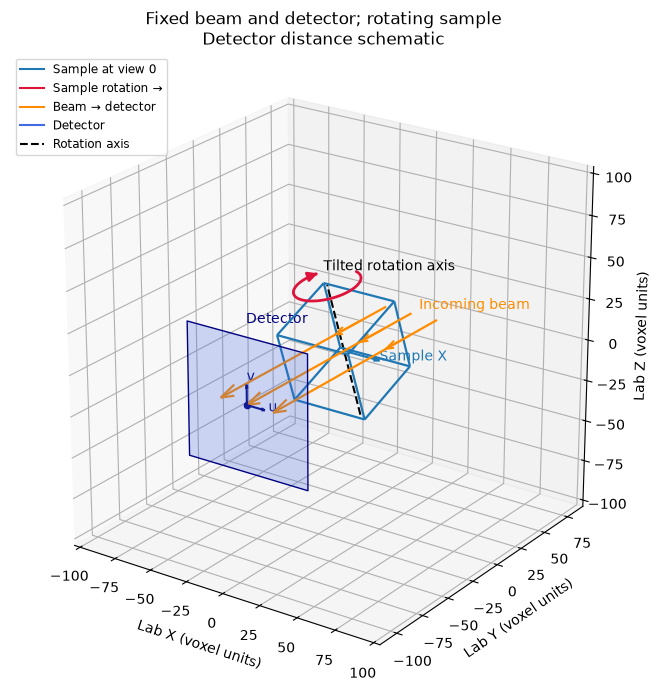

In [2]:
size = 48
view_count = 180
tilt_degrees = 70.0
cgls_iterations = 20
device_index = 0
# Each entry contains an XYZ centre, radius and attenuation per unit length.
spheres = [
    ((-8.0, -3.0, -4.0), 7.0, 1.0),
    ((8.0, 5.0, 4.0), 6.0, 0.6),
    ((1.0, -8.0, 10.0), 4.0, 0.8),
]
grid = Volume3DGeometry(shape=(size, size, size))
scan = Parallel3DGeometry.laminography(
    angles=np.linspace(0, 2 * np.pi, view_count, endpoint=False),
    detector_shape=(80, 80),
    tilt_angle=np.deg2rad(tilt_degrees),
)

coordinates = np.arange(size, dtype=np.float32) - (size - 1) / 2
z, y, x = np.meshgrid(coordinates, coordinates, coordinates, indexing="ij")
phantom = np.zeros(grid.shape, dtype=np.float32)
for (cx, cy, cz), radius, attenuation in spheres:
    inside = (x - cx) ** 2 + (y - cy) ** 2 + (z - cz) ** 2 <= radius**2
    phantom[inside] += attenuation

figure, ax = plot_geometry(scan, grid, view_indices=[0], frame="laboratory")
figure.tight_layout()
plt.show()

## Generate analytical line integrals
For a ray at perpendicular distance d from a sphere centre, its path length
is 2 sqrt(radius**2 - d**2), or zero outside the sphere. Multiplying by the
sphere attenuation gives its contribution to the measured line integral.
These are ideal point-ray measurements, without detector averaging or noise.

In [3]:
rows, columns = scan.detector_shape
row_positions = np.arange(rows) - (rows - 1) / 2
column_positions = np.arange(columns) - (columns - 1) / 2
projections = np.zeros(scan.projection_shape, dtype=np.float32)
for view, vector in enumerate(scan.to_vectors()):
    ray, centre, u, v = vector.reshape(4, 3)
    ray = ray / np.linalg.norm(ray)
    pixels = (
        centre + row_positions[:, None, None] * v + column_positions[None, :, None] * u
    )
    for sphere_centre, radius, attenuation in spheres:
        offset = pixels - np.asarray(sphere_centre)
        perpendicular = offset - (offset @ ray)[..., None] * ray
        distance_squared = np.sum(perpendicular**2, axis=-1)
        chord = 2 * np.sqrt(np.maximum(radius**2 - distance_squared, 0))
        projections[:, view, :] += (attenuation * chord).astype(np.float32)

print(f"Projection shape (detY, angles, detX): {projections.shape}")

Projection shape (detY, angles, detX): (80, 180, 80)


## Reconstruct with FBP and CGLS
FBP uses the trajectory's full-turn angular normalisation and tilt factor.
CGLS fits the original line integrals using the ASTRA vector projector.
Disabling output masks keeps the same full volume for both comparisons.

In [4]:
with RecToolsDIR(
    projection_geometry=scan, volume_geometry=grid, device_index=device_index
) as direct:
    fbp = direct.FBP(projections, filter_type="RAM-LAK", recon_mask_radius=None)

with RecToolsIR(
    projection_geometry=scan,
    volume_geometry=grid,
    device_index=device_index,
    backend="astra",
) as iterative:
    cgls = cp.asnumpy(
        iterative.CGLS(projections, iterations=cgls_iterations, recon_mask_radius=None)
    )

for name, image in [("FBP", fbp), ("CGLS", cgls)]:
    rmse = np.sqrt(np.mean((image - phantom) ** 2))
    print(f"{name} RMSE over the full volume: {rmse:.5f}")

FBP RMSE over the full volume: 0.03819
CGLS RMSE over the full volume: 0.03206


## Inspect axial and side views
Axial sections cut across the sample rotation axis; coronal sections include
that axis. Compare feature locations, boundary sharpness and spreading along
Z. The missing cone, discretisation and iteration count all affect the result.
Raising the CGLS iteration count cannot supply measurements absent from the
acquisition. Changing tilt_degrees towards 90 approaches tomography; tilted
FBP still requires a uniformly sampled full turn.

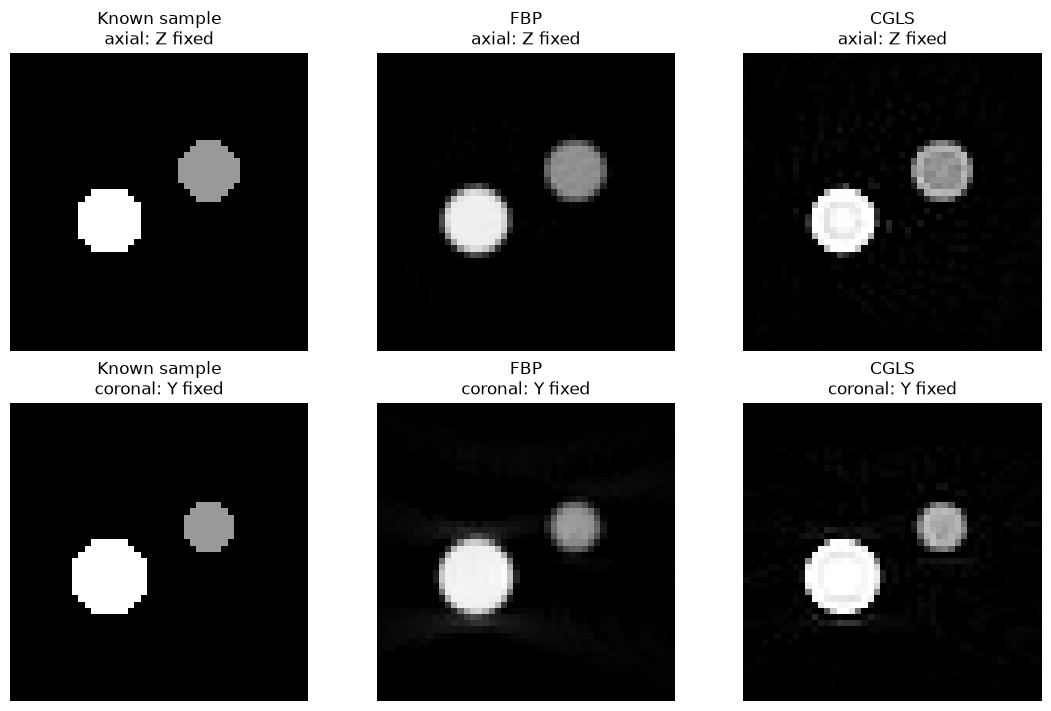

In [5]:
figure, axes = plt.subplots(2, 3, figsize=(11, 7), constrained_layout=True)
middle = size // 2
for column, (name, image) in enumerate(
    [("Known sample", phantom), ("FBP", fbp), ("CGLS", cgls)]
):
    for row, (label, section) in enumerate(
        [("axial: Z fixed", image[middle]), ("coronal: Y fixed", image[:, middle, :])]
    ):
        axes[row, column].imshow(section, origin="lower", cmap="gray", vmin=0, vmax=1)
        axes[row, column].set_title(f"{name}\n{label}")
        axes[row, column].set_axis_off()
plt.show()